# Preliminary Statistical Analysis of Language in Complaints with Descriptions
this notebook is meant to create some preliminary understanding of language frequently used in combination of our findings using LLMs and visualize our findings 


In [21]:
# Importing all necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
import re

In [4]:
df_complaints = pd.read_csv('../Joining Datasets/Data/Complaints_with_description.csv')

df_complaints.head()

,IA No,Incident type,Received date,Title/rank (snap),First name,Last name,Allegation,Finding,Action taken,Action taken date,Days or hours suspended,Disposition,Priority,Occurred date,Description,clean_name
0,IAD2016-0005,Citizen complaint,2016-01-04,P.O.,Ana c,Almeida,Respectful Treatment,Sustained,Oral Reprimand,2020-07-23 00:00:00,NaN,Sustained,NaN,2015-12-28,I live on 15 Adams st and Ana Almeida's mother...,anacalmeida
1,IAD2016-0108,Internal investigation,2016-01-04,P.O.,Eric T.,Schmidt,Prisoners/Booking Procedures,Sustained,Oral Reprimand,2019-07-09 00:00:00,NaN,Sustained,NaN,2015-12-21,"On Monday 12/21/15, PO Schmidt notified DS of ...",erictschmidt
2,IAD2016-0006,Internal investigation,2016-01-07,P.O.,Matthew S.,McCabe,Reporting for Duty,Sustained,Oral Reprimand,2015-12-24 00:00:00,NaN,Sustained,NaN,2015-07-11,"(Rule 102,10c) PO Matthew McCabe is alleged to...",matthewsmccabe
3,IAD2016-0010,Internal investigation,2016-01-11,P.O.,Donroy G,Grant,Association with Criminals,Sustained,Termination,2020-03-05 00:00:00,NaN,Sustained,NaN,2015-04-26,Officer Donroy Grant was involved an an incide...,donroyggrant
4,IAD2016-0010,Internal investigation,2016-01-11,P.O.,Donroy G,Grant,Conduct Unbecoming,Sustained,Termination,2020-03-05 00:00:00,NaN,Sustained,NaN,2015-04-26,Officer Donroy Grant was involved an an incide...,donroyggrant


In [5]:
#remove any rows with missing values in the 'Description' or 'Allegation' columns
df_complaints = df_complaints.dropna(subset=['Description', 'Allegation'])

In [6]:
# set all the text in the 'Description' and 'Allegation' columns to lowercase
df_complaints['Description'] = df_complaints['Description'].str.lower()
df_complaints['Allegation'] = df_complaints['Allegation'].str.lower()

In [7]:
df_complaints['Allegation'].unique()
unique_allegations = df_complaints['Allegation'].unique().tolist()

In [8]:
value_count_allegations = df_complaints["Allegation"].value_counts()

In [21]:
print("Unique Allegations:", unique_allegations)

Unique Allegations: ['respectful treatment', 'prisoners/booking procedures', 'reporting for duty', 'association with criminals', 'conduct unbecoming', 'untruthfulness in department report', 'directives/orders', 'drug test', 'neg.duty/unreasonable judge', 'conformance to laws', 'self identification', 'alcohol off duty', 'conformance to laws (3 counts)', 'abuse of process', 'use of force', 'cjis access', 'tabacco on duty', 'special order 99-48 dept e-mail and computer use', 'bias-free policing policy', 'detail cards', 'paid details fitness for duty', 'permissible weapons & ammunition', 'uniforms and equipment', 'neg.duty/unreasonable judge bias', 'emergency driving', 'police service', 'booking procedures', 'situations involving off-duty boston p.o.s', 'change of address notification violation', 'residency', 'untruthfulness', 'conformance to laws (2 counts)', 'situations involving family & frien', 'investigation of use of force', 'respectful treatment (2 counts)', 'f.i.o reports', 'report

In [9]:
# standardized label -> every raw variant (lowercase) that should collapse into it
GROUPS = {
 "Respectful Treatment": ["respectful treatment","respectful treatment (2 counts)","respectful treatment (3 counts)","respectful treatment bias","nrespectful treatment"],
 "Neglect of Duty / Unreasonable Judgment": ["neg.duty/unreasonable judge","neg.duty/unreasonable judge bias","neg.duty/unreasonable judge (2 counts)","neg.duty/unreasonable judge (2 counts","negduty/unreasonable judge","inegduty/unreasonable judge","unreasonable judgment bias","neglect of duty","negelct of duty","neglect of duty/unreasonable judgement","neglect of duty/unreasonable judgment (2 counts)","neglect of duty/unreasonable judgment (3 counts)","neglect of duty/unreasonable judgment (4 counts)","neglect of duty/unreasonable judgment (11 counts)"],
 "Use of Force": ["use of force","use of force (2 counts)"],
 "Investigation of Use of Force": ["investigation of use of force"],
 "Conduct Unbecoming": ["conduct unbecoming","conduct unbecoming (2 counts)","conduct unbecoming (3 counts)","conduct unbecoming (7 counts)","rule 102 sec. 3 - conduct","i"],
 "Conformance to Laws": ["conformance to laws","conformance to laws (2 counts)","conformance to laws (2counts)","conformance to laws (3 counts)","conformance to laws (11 counts)","conformance to laws (7 counts)","rule 102 sec. 35 - conformance to laws"],
 "Self Identification": ["self identification"],
 "Display of Identification": ["display of identification"],
 "BIAS-Free Policing Policy": ["bias-free policing policy"],
 "Abuse of Process": ["abuse of process"],
 "Abuse of Discretion": ["abuse of discretion"],
 "Police Service": ["police service"],
 "Manner of Recording Complaints": ["manner of recording complaints"],
 "Strip Search / Visual Body Cavity Search": ["strip search and or visual body cavity search"],
 "Search Suspect After Handcuffing": ["search suspect after handcuffing"],
 "Prisoner Handling / Booking Procedures": ["prisoners/booking procedures","booking procedures","handcuffs","prisoners","prisoners - cell inspection","prisoner inspection","prisoner - sickness or injury"],
 "Untruthfulness / Inaccurate Reporting": ["untruthfulness","untruthfulness (2 counts)","untruthfulness (3 counts)","untruthfulness in department report","untruthfulness in department reports (2 counts)","untruthfulness in department reports (3 counts)","untruthfulness in department reports (4 counts)","knowingly entering inaccurate false or improper information","department reports-truthfulness","department reports-inacurrate reporting"],
 "Accountability": ["accountability"],
 "Improper Statements": ["improper statements"],
 "Statement of Opinion": ["statement of opinion (6 counts)"],
 "Request for Interviews": ["request for interviews (6 counts)"],
 "Canon Seven": ["canon seven"],
 "Canon Eight": ["canon eight"],
 "CJIS / CORI Access": ["cjis access","cjis access (4 counts)","cori access","cori violation","cori procedures"],
 "Association with Criminals": ["association with criminals","association with criminals (2 counts)"],
 "Personal Business": ["personal business"],
 "Evidence & Found Property": ["evidence & found property"],
 "Safeguarding Non-Evidence Property": ["safeguarding non-evidence property"],
 "Handling & Disposition of Seized Money": ["handling & disposistion of seized money"],
 "Release of Property in Police Custody": ["release of property in police custody"],
 "Courts": ["courts"],
 "Courts - Failure to Appear When Summonsed": ["courts - failure to appear when summonsed (4 counts)"],
 "Alcohol on Duty": ["alcohol on duty","alcohol on duty (2 counts)","alcohol on duty (3 counts)"],
 "Alcohol in Police Facility": ["alcohol in police facility","alcohol in police facility (2 counts)","alcohol in police facility (3 counts)"],
 "Alcohol off Duty": ["alcohol off duty","alcohol off duty (5 counts)","rule 102 sec. 14 - use of alcohol off duty"],
 "Drug Testing / Controlled Substances": ["drug test","drug test (2 counts)","substance abuse policy","controlled substances","controlled substance notification (8 counts)","under the influence","prohibited conduct"],
 "Tobacco on Duty": ["tabacco on duty"],
 "Reporting for Duty": ["reporting for duty","reporting for duty (2 counts)","reporting for duty (3 counts)","officer unable to report for duty"],
 "Paid Details": ["paid details","paid details fitness for duty","detail cards","authorized details","paid detail authorized vendor","acceptance of details","acceptance of details (2 counts)","paid detail assignment"]
              + [f"paid detail assignment ({n} counts)" for n in (3,4,8,16,17,18,20,21,23,41,44,71,89,98,131)],
 "Directives / Orders": ["directives/orders","directives/orders (3 counts)","directives/orders (5 counts)","directives & orders (2 counts)","directives & orders (3 counts)"],
 "Failure to Notify Supervisor When Leaving Assigned Post": ["failure to notify supervisor when leaving their assigned post"],
 "P.O. Notifying Operations": ["p.o. notifying operations (3 counts)","p.o. notifying operations (9 counts)"],
 "Sleeping on Duty": ["sleeping on duty"],
 "Sick Leave": ["sick leave"],
 "Leaves of Absence": ["leaves of absence"],
 "Off Duty Employment w/out Permission": ["off duty employment w/out permission"],
 "Residency": ["residency"],
 "Change of Address Notification Violation": ["change of address notification violation"],
 "Residence and Telephone": ["residence and telephone"],
 "Uniform & Equipment": ["uniforms and equipment","uniform specifications","uniform & equipment-care & maintenance","uniform & equipment - shoes","uniform & equipment - trousers"],
 "Body-Worn Camera Policy": ["special order 16-023 section 2.5 bwc notice of recording","body worn camera policy - categorization","body worn policy - activation & incidents of use","bwc activation & incidents of use"],
 "Vehicle Operation / Accidents": ["emergency driving","emergency driving weather & enviornmental conditions","dept. motor vehicle accidents","department motor vehicle accidents notifications"],
 "Permissible Weapons & Ammunition": ["permissible weapons & ammunition"],
 "Reporting Firearms Discharge": ["reporting firearms dishcarge"],
 "Securing and Maintenance of Firearm": ["securing and maintenance of firearm"],
 "Failing to Submit Reports in Timely Manner": ["failing to submit reports in timely manner"],
 "Duty Supervisor": ["duty supervisor"],
 "Area Commanders": ["area commanders"],
 "Special Order 99-48 Dept E-Mail and Computer Use": ["special order 99-48 dept e-mail and computer use"],
 "Violations of Rules & Procedures": ["violations of rules & procedures"],
 "Failure to Be Knowledgeable & Informed": ["failure to be knowledgeable & informed"],
 "Mutual Protection": ["mutual protection"],
 "Information Dept. Members May Not Release": ["information dep.o. members may not release"],
 "Criminal Complaints": ["criminal complaints"],
 "Radio Procedures": ["radio procedures"],
 "F.I.O Reports": ["f.i.o reports"],
 "Completion of FIOE Report": ["completion of fioe report"],
 "Harassment Policy / Sexual Harassment": ["harassment policy","harassment policy - confidentiality","harassment policy - retaliation","harassment policy - retaliation (2 counts)","harassment policy - retaliation (3 counts)","sexual harassment - supervisor responsibilities","sexual harassment - unlawful conduct/harassment"],
 "Hostile Work Environment": ["hostile work environment","hostile work environment (6 counts)"],
 "Situations Involving Family / Domestic": ["situations involving family & frien","situations involving family members","domestic situations involving dep.o. employees"],
 "Situations Involving Off-Duty Boston P.O.s": ["situations involving off-duty boston p.o.s"],
}

# flip into the plain dictionary you apply to the column
allegation_map = {raw: clean for clean, raws in GROUPS.items() for raw in raws}

In [10]:
# flag bias-labeled rows BEFORE they get merged into their parent allegation
df_complaints["bias_label"] = df_complaints["Allegation"].str.contains("bias", case=False, na=False)

key = (df_complaints["Allegation"].astype(str).str.strip().str.lower()
         .str.replace(r"\s+", " ", regex=True))
df_complaints["allegation_clean"] = key.map(allegation_map)

In [58]:
df_complaints.head()


,IA No,Incident type,Received date,Title/rank (snap),First name,Last name,Allegation,Finding,Action taken,Action taken date,...,Gun pointed,Denied medical attention,Shot,Firearm discharged,Life-threatening,Unresponsive,Death,Touched private parts,Strip search,Threatened to kill
0,IAD2016-0005,Citizen complaint,2016-01-04,P.O.,Ana c,Almeida,respectful treatment,Sustained,Oral Reprimand,2020-07-23 00:00:00,...,0,0,0,0,0,0,0,0,0,0
1,IAD2016-0108,Internal investigation,2016-01-04,P.O.,Eric T.,Schmidt,prisoners/booking procedures,Sustained,Oral Reprimand,2019-07-09 00:00:00,...,0,0,0,0,0,0,0,0,0,0
2,IAD2016-0006,Internal investigation,2016-01-07,P.O.,Matthew S.,McCabe,reporting for duty,Sustained,Oral Reprimand,2015-12-24 00:00:00,...,0,0,0,0,0,0,0,0,0,0
3,IAD2016-0010,Internal investigation,2016-01-11,P.O.,Donroy G,Grant,association with criminals,Sustained,Termination,2020-03-05 00:00:00,...,0,0,0,0,0,0,0,0,0,0
4,IAD2016-0010,Internal investigation,2016-01-11,P.O.,Donroy G,Grant,conduct unbecoming,Sustained,Termination,2020-03-05 00:00:00,...,0,0,0,0,0,0,0,0,0,0


In [17]:
DOMAIN_STOP = {"officer","officers","po","police","boston","bpd","department","dept","alleged","allegedly",
               "said","says","told","stated","complainant","complaint","incident","rule","102","sec","section",
               "mr","ms","mrs","pm","am","street","st","ave","avenue"}
STOP = list(ENGLISH_STOP_WORDS | DOMAIN_STOP)

In [19]:
cv = CountVectorizer(ngram_range=(1, 2), stop_words=STOP, min_df=5, binary=True)
X = cv.fit_transform(df_complaints["Description"])
vocab = np.array(cv.get_feature_names_out())

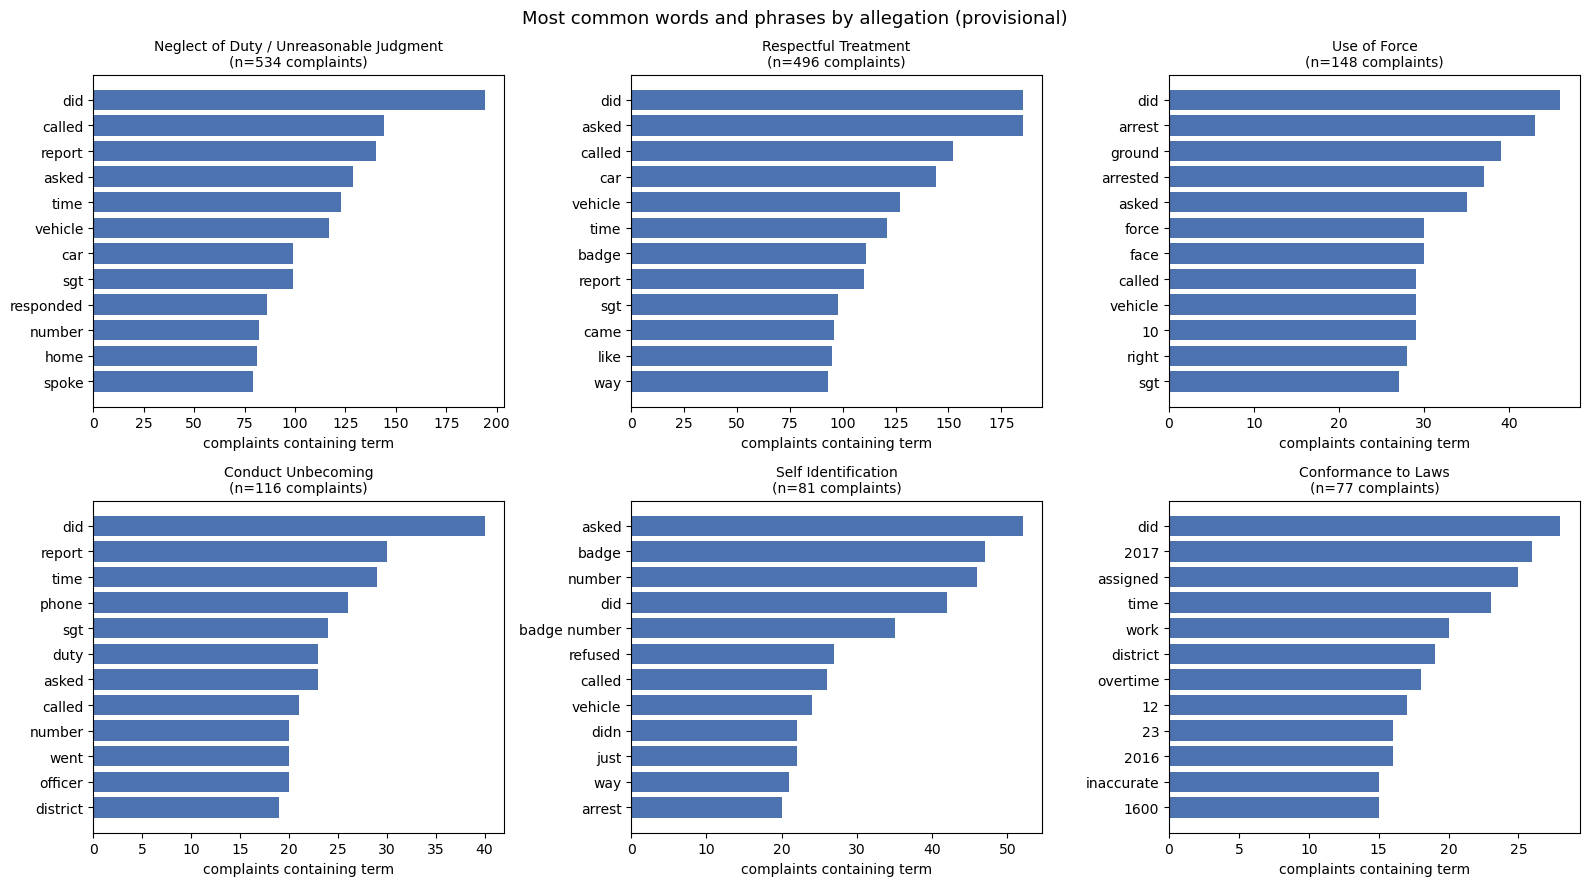

In [32]:
top_alleg = df_complaints["allegation_clean"].value_counts().head(6).index
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, a in zip(axes.ravel(), top_alleg):
    rows = (df_complaints["allegation_clean"] == a).values
    counts = np.asarray(X[rows].sum(0)).ravel()
    idx = counts.argsort()[::-1][:12]
    ax.barh(vocab[idx][::-1], counts[idx][::-1], color="#4C72B0")
    ax.set_title(f"{a}\n(n={rows.sum()} complaints)", fontsize=10)
    ax.set_xlabel("complaints containing term")
fig.suptitle("Most common words and phrases by allegation (provisional)", fontsize=13)
fig.tight_layout()

In [ ]:
CATEGORY_COL = "allegation_clean"

# CHANGE THIS to the name of your complaint/narrative column.
TEXT_COL = "Description"

# ============================================================
# 2. DEFINE KEYWORD CONCEPTS
# ============================================================
# Each concept has a regular expression that includes variations.
# Matching is case-insensitive and uses word boundaries.
# Counts are calculated separately for every record.

KEYWORDS = {
    # Force and violence
    "Force": r"\bforce\b",
    "Excessive force": r"\bexcessive force\b",
    "Unnecessary force": r"\bunnecessary force\b",
    "Use of force": r"\buse of force\b",
    "Police brutality": r"\bpolice brutality\b",
    "Brutality": r"\bbrutalit(?:y|ies)\b",
    "Brutal": r"\bbrutal(?:ly)?\b",
    "Violence": r"\bviolence\b",
    "Violent": r"\bviolent(?:ly)?\b",
    "Deadly force": r"\bdeadly force\b",

    # Physical actions
    "Assault": r"\bassault(?:s|ed|ing)?\b",
    "Hit": r"\bhit(?:s|ting)?\b",
    "Punch": r"\bpunch(?:es|ed|ing)?\b",
    "Kick": r"\bkick(?:s|ed|ing)?\b",
    "Slap": r"\bslap(?:s|ped|ping)?\b",
    "Beat": r"\bbeat(?:s|en|ing)?\b",
    "Choke": r"\bchok(?:e|es|ed|ing)\b",
    "Push": r"\bpush(?:es|ed|ing)?\b",
    "Shove": r"\bshov(?:e|es|ed|ing)\b",
    "Grab": r"\bgrab(?:s|bed|bing)?\b",
    "Slam": r"\bslam(?:s|med|ming)?\b",
    "Throw": r"\bthrow(?:s|n|ing)?\b",
    "Drag": r"\bdrag(?:s|ged|ging)?\b",
    "Restrain": r"\brestrain(?:s|ed|ing)?\b|\brestraint\b",
    "Handcuff": r"\bhandcuff(?:s|ed|ing)?\b",
    "Twisted arm": r"\btwist(?:ed|s|ing)? arm\b",
    "Struck": r"\bstruck\b",
    "Got in my face": r"\bgot in my face\b",

    # Threats and interpersonal conduct
    "Threat": r"\bthreat(?:s|en|ened|ening)?\b",
    "Threatened to arrest": r"\bthreatened to arrest\b",
    "Harassment": r"\bharass(?:es|ed|ing)?\b|\bharassment\b",
    "Intimidation": r"\bintimidat(?:e|es|ed|ing|ion)\b",
    "Disrespect": r"\bdisrespect(?:s|ed|ful|fully)?\b",
    "Rude": r"\brude(?:ly|ness)?\b",
    "Unprofessional": r"\bunprofessional\b",
    "Attitude": r"\battitude\b",
    "Dismissive": r"\bdismissive(?:ly)?\b",
    "Condescending": r"\bcondescend(?:ing|ed|s)?\b|\bcondescension\b",
    "Did not listen": r"\bdid not listen\b|\bwould not listen\b",
    "Would not let me explain": r"\bwould not let me explain\b|\bwouldn't let me explain\b",
    "Made to wait": r"\bmade me wait\b|\bmade to wait\b",
    "Put on hold": r"\bput me on hold\b|\bput on hold\b",
    "Curt or abrupt": r"\bcurt\b|\babrupt\b",
    "Hung up on me": r"\bhung up on me\b",
    "Refused name or badge": r"\brefused to give (?:me )?(?:his |her |their )?(?:name|badge number)\b",
    "Yelled": r"\byell(?:s|ed|ing)?\b",
    "Screamed": r"\bscream(?:s|ed|ing)?\b",
    "Shouted": r"\bshout(?:s|ed|ing)?\b",
    "Insulted": r"\binsult(?:s|ed|ing)?\b",
    "Name-calling": r"\bname.?calling\b",
    "Mocked": r"\bmock(?:s|ed|ing|ery)?\b",
    "Taunted": r"\btaunt(?:s|ed|ing)?\b",
    "Confrontational": r"\bconfrontational\b",
    "Profanity": r"\b(?:fuck|fucking|bitch|asshole|bastard|shit|damn)\b",
    "Shut the fuck up": r"\bshut the fuck up\b",
    "Retaliation": r"\bretaliat(?:e|es|ed|ing|ion)\b",

    # Discrimination
    "Racism": r"\bracis(?:m|t|ts|tic)\b",
    "Racial": r"\bracial\b",
    "Profiling": r"\bprofil(?:e|ed|ing)\b|\bracial profiling\b",
    "Discrimination": r"\bdiscriminat(?:e|es|ed|ing|ion|ory)\b",
    "Racial slurs": r"\bracial slur(?:s)?\b",
    "Anti-LGBT slurs": r"\banti.?lgbt slur(?:s)?\b",
    "Disability or mental health remarks": (
        r"\bdisabilit(?:y|ies)\b|\bmental health\b"
    ),
    "Sexual insults": r"\bsuck his dick\b|\bsexual insult(?:s)?\b",
    "Search without consent": r"\bsearched without consent\b",
    "Entered without warrant": r"\bentered without (?:a )?warrant\b",

    # Injuries and potentially dangerous actions
    "Injury": r"\binjur(?:y|ies|ed|es|ing)\b",
    "Broken bone": r"\bbroken\b|\bbroke\b",
    "Fracture": r"\bfractur(?:e|es|ed|ing)\b",
    "Dislocation": r"\bdislocat(?:e|es|ed|ing|ion)\b",
    "Hospital": r"\bhospital(?:s|ized|isation|ization)?\b",
    "Surgery": r"\bsurger(?:y|ies)\b",
    "Knee on neck or back": r"\bknee on (?:my )?(?:neck|back)\b",
    "Pepper spray": r"\bpepper spray\b",
    "OC spray": r"\boc spray\b|\boleoresin capsicum\b",
    "Baton": r"\bbaton(?:s)?\b",
    "Gun pointed": r"\bgun (?:was )?pointed\b|\bpointed (?:a )?gun\b",
    "Denied medical attention": r"\bdenied (?:me )?medical attention\b",
    "Shot": r"\bshot\b|\bshoot(?:s|ing)?\b",
    "Firearm discharged": r"\bfirearm discharged\b",
    "Life-threatening": r"\blife.?threatening\b",
    "Unresponsive": r"\bunresponsive\b",
    "Death": r"\bdeath\b|\bdeaths\b|\bdied\b|\bdead\b",
    "Touched private parts": r"\btouched my private parts\b",
    "Strip search": r"\bstrip search(?:es|ed|ing)?\b",
    "Threatened to kill": r"\bthreatened to kill\b",
}



# COUNT OCCURRENCES FOR EACH RECORD
def count_matches(text, pattern):
    """Count non-overlapping matches of a concept in one record."""
    return len(re.findall(pattern, str(text), flags=re.IGNORECASE))


for concept, pattern in KEYWORDS.items():
    df_complaints[concept] = df_complaints[TEXT_COL].apply(
        lambda text: count_matches(text, pattern)
    )

# Binary version: 1 if a record mentions the concept at least once.
# Use this for co-occurrence and correlation analysis.
binary_df = df_complaints[list(KEYWORDS)].gt(0).astype(int)


# ============================================================
# SUMMARIZE BY CATEGORY IN COLUMN ALLEGATION_CLEAN
# ============================================================

# Total mentions of each concept within each category
category_counts = df_complaints.groupby(CATEGORY_COL)[list(KEYWORDS)].sum()

# Number of records in each category
category_sizes = df_complaints.groupby(CATEGORY_COL).size()

# Number of records in each category mentioning each concept
category_presence = binary_df.groupby(df_complaints[CATEGORY_COL]).sum()

# Percentage of records in each category mentioning each concept
category_prevalence = category_presence.div(
    category_sizes, axis=0
) * 100

print("Category counts:\n", category_counts)
print("Category presence:\n", category_presence)
print("Category prevalence:\n", category_prevalence)


Category counts:
                                        Force  Excessive force  \
allegation_clean                                                
Abuse of Discretion                        0                0   
Abuse of Process                           5                3   
Accountability                             0                0   
Alcohol in Police Facility                13                0   
Alcohol off Duty                           0                0   
...                                      ...              ...   
Uniform & Equipment                        0                0   
Untruthfulness / Inaccurate Reporting      1                0   
Use of Force                              33               14   
Vehicle Operation / Accidents              2                0   
Violations of Rules & Procedures           0                0   

                                       Unnecessary force  Use of force  \
allegation_clean                                              

'# Save all results to Excel\nwith pd.ExcelWriter("keyword_analysis.xlsx") as writer:\n    category_counts.to_excel(writer, sheet_name="Total Mentions")\n    category_presence.to_excel(writer, sheet_name="Records Mentioning")\n    category_prevalence.to_excel(writer, sheet_name="Percent of Records")\n    df_complaints.to_excel(writer, sheet_name="Record Level Data", index=False)\n\nprint("Saved keyword_analysis.xlsx")\n'

In [ ]:
# Save each results table as a separate CSV file
"""category_counts.to_csv("total_mentions.csv")
category_presence.to_csv("records_mentioning.csv")
category_prevalence.to_csv("percent_of_records.csv")
df_complaints.to_csv("record_level_data.csv", index=False)

print("Saved all results as CSV files!")"""

Saved all results as CSV files!


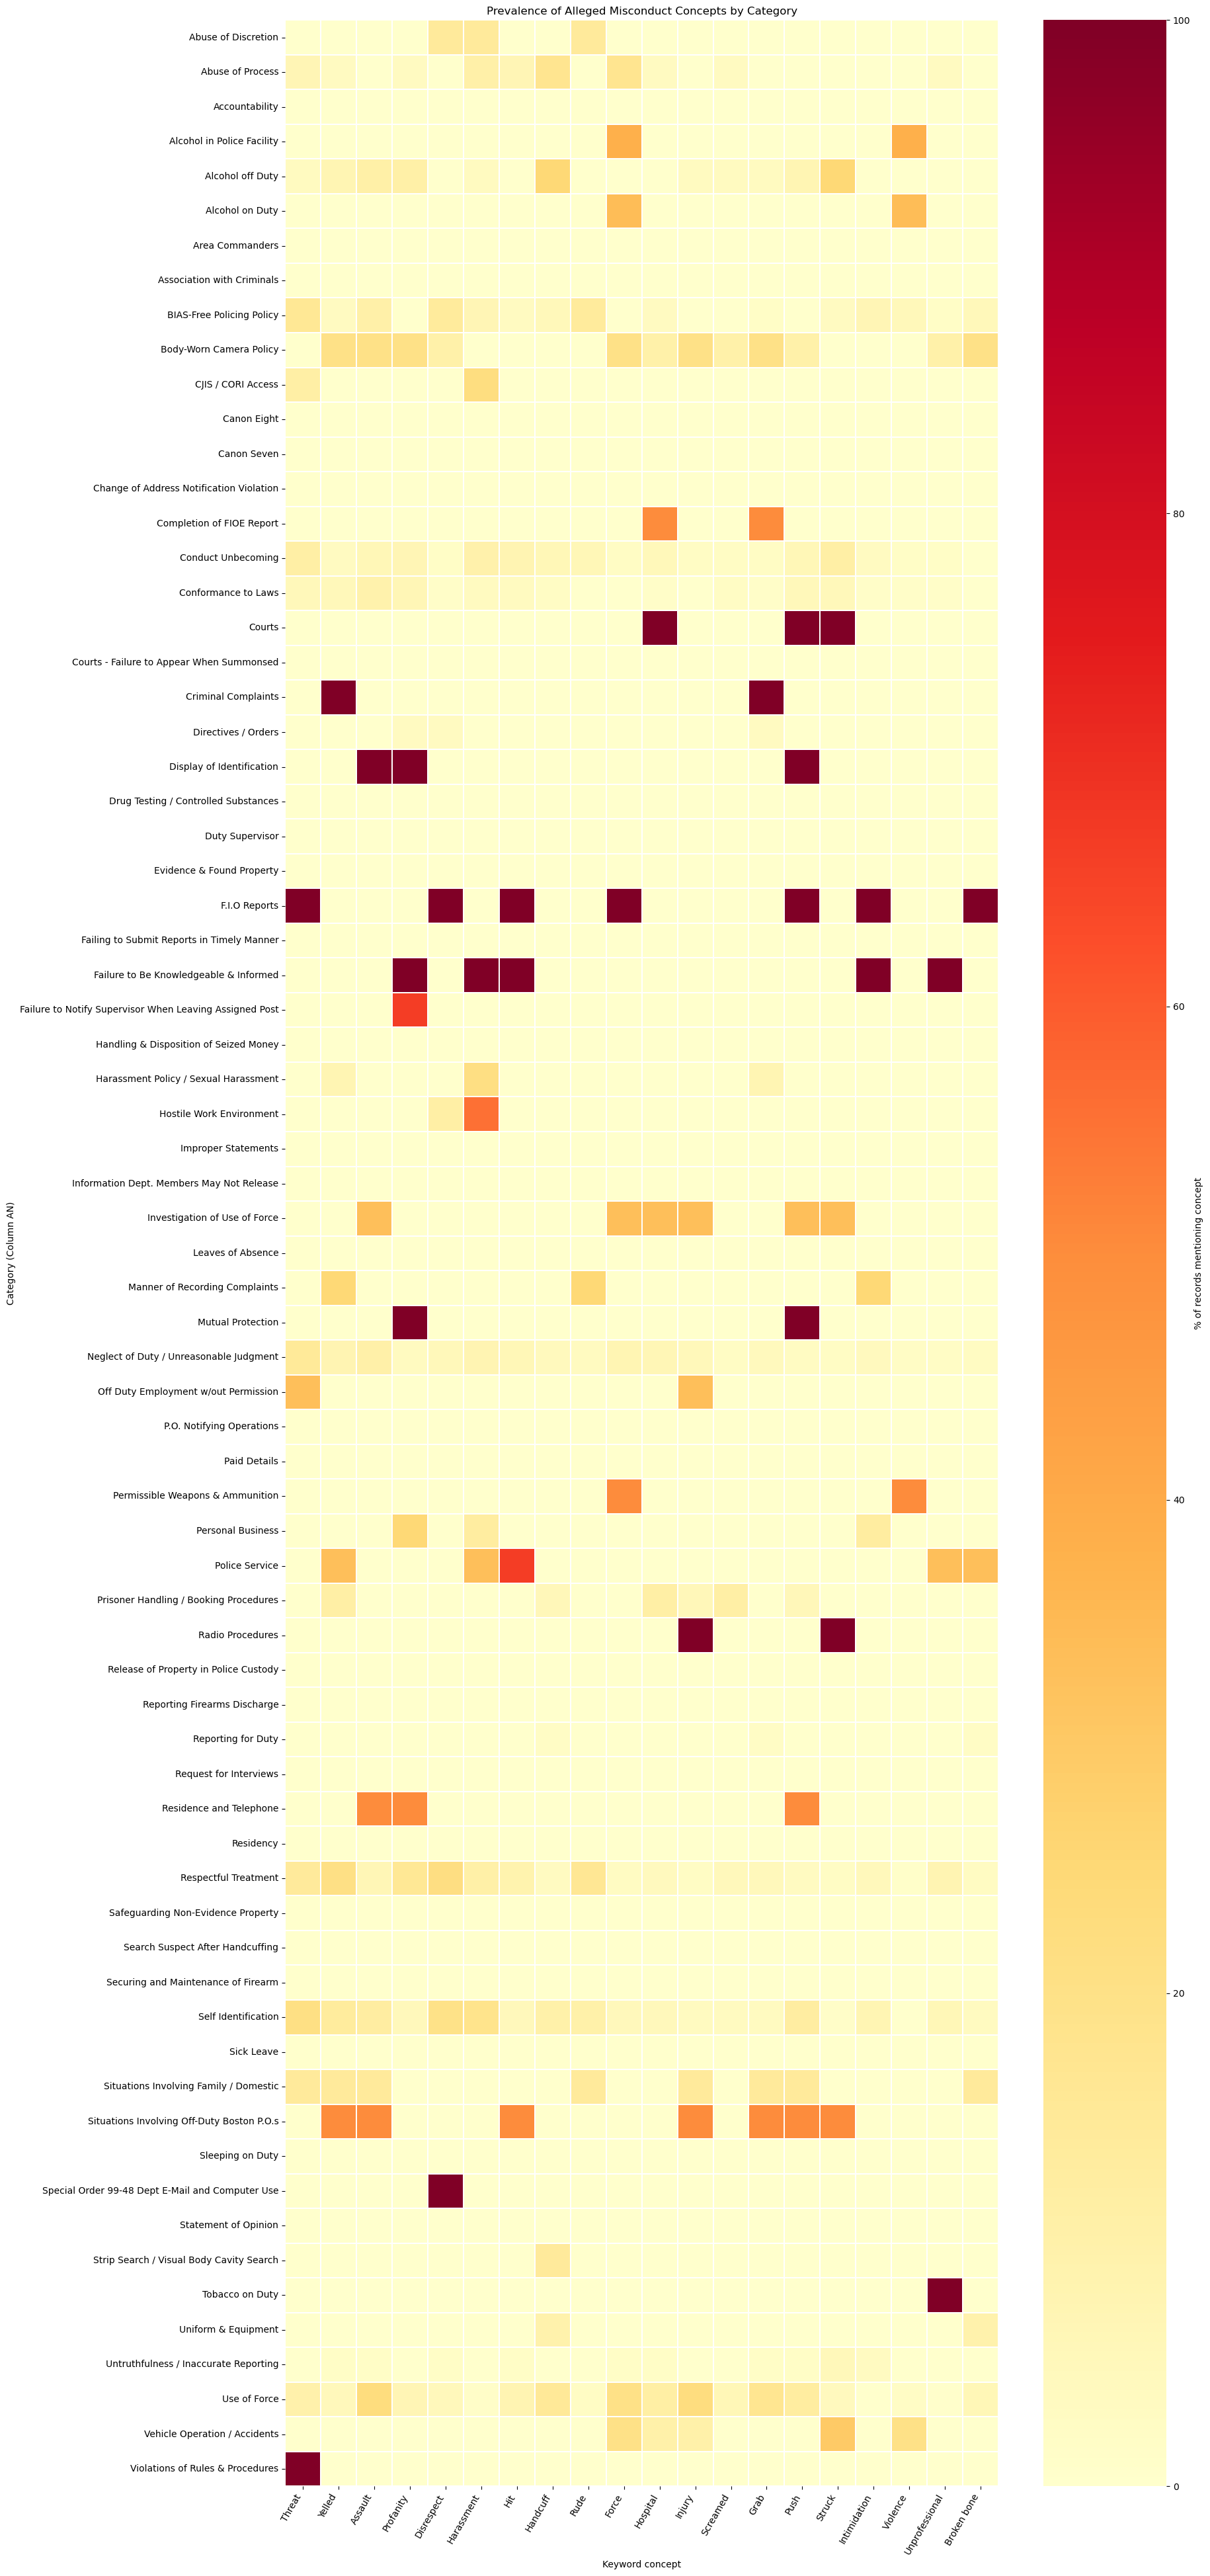

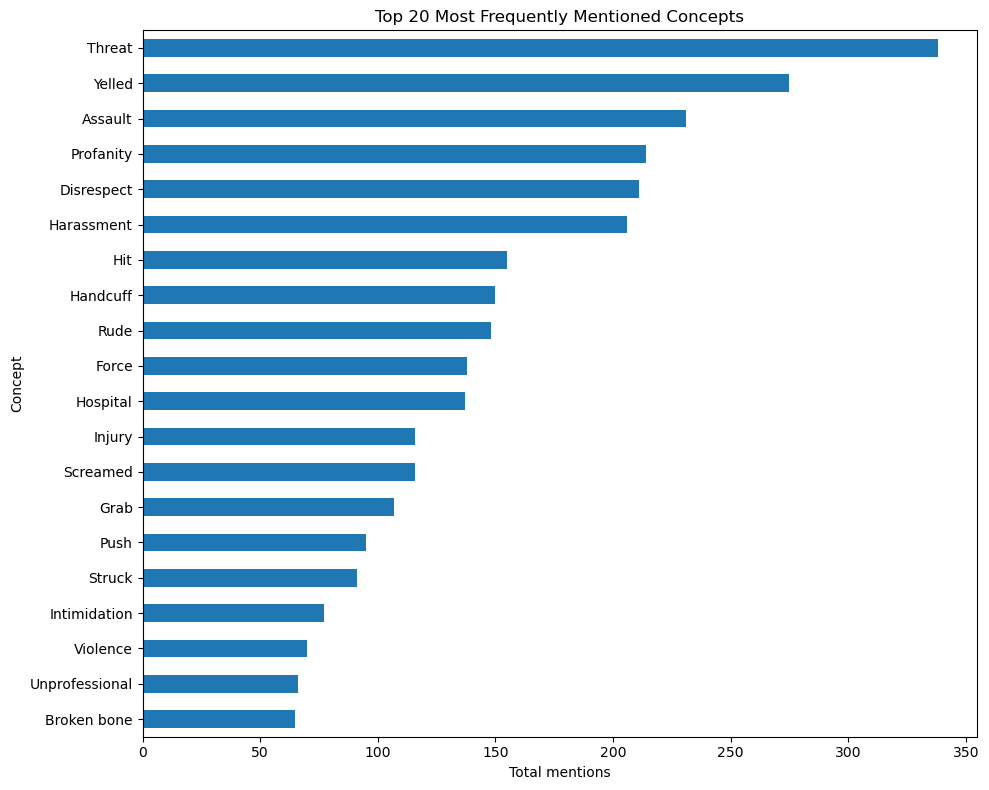

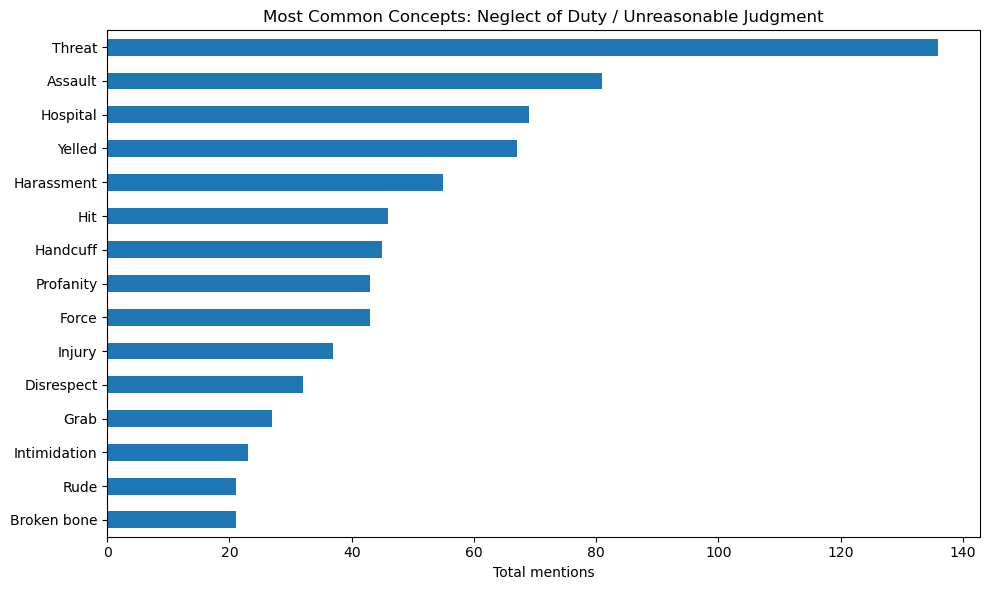

In [ ]:
# ============================================================
# 5. HEATMAP: KEYWORDS BY CATEGORY
# ============================================================

# Select the 20 most frequently mentioned concepts overall.
top_concepts = (
    df_complaints[list(KEYWORDS)].sum()
    .sort_values(ascending=False)
    .head(20)
    .index
)

plt.figure(figsize=(18, max(6, len(category_prevalence) * 0.55)))

sns.heatmap(
    category_prevalence[top_concepts],
    cmap="YlOrRd",
    linewidths=0.3,
    annot=False,
    cbar_kws={"label": "% of records mentioning concept"}
)

plt.title("Prevalence of Alleged Misconduct Concepts by Category")
plt.xlabel("Keyword concept")
plt.ylabel("Category (Column AN)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


# ============================================================
# 6. BAR CHART: MOST COMMON CONCEPTS OVERALL
# ============================================================

overall_mentions = df_complaints[list(KEYWORDS)].sum().sort_values(
    ascending=True
)

top_20 = overall_mentions.tail(20)

plt.figure(figsize=(10, 8))
top_20.plot(kind="barh")

plt.title("Top 20 Most Frequently Mentioned Concepts")
plt.xlabel("Total mentions")
plt.ylabel("Concept")
plt.tight_layout()
plt.show()


# ============================================================
# 7. COMPARE CONCEPTS WITHIN ONE CATEGORY
# ============================================================

# Change this to a category value that exists in column ALLEGATION_CLEAN.
selected_category = df_complaints[CATEGORY_COL].value_counts().index[0]

category_data = df_complaints[df_complaints[CATEGORY_COL] == selected_category]

category_mentions = (
    category_data[list(KEYWORDS)]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 6))
category_mentions.plot(kind="barh")

plt.title(f"Most Common Concepts: {selected_category}")
plt.xlabel("Total mentions")
plt.tight_layout()
plt.show()



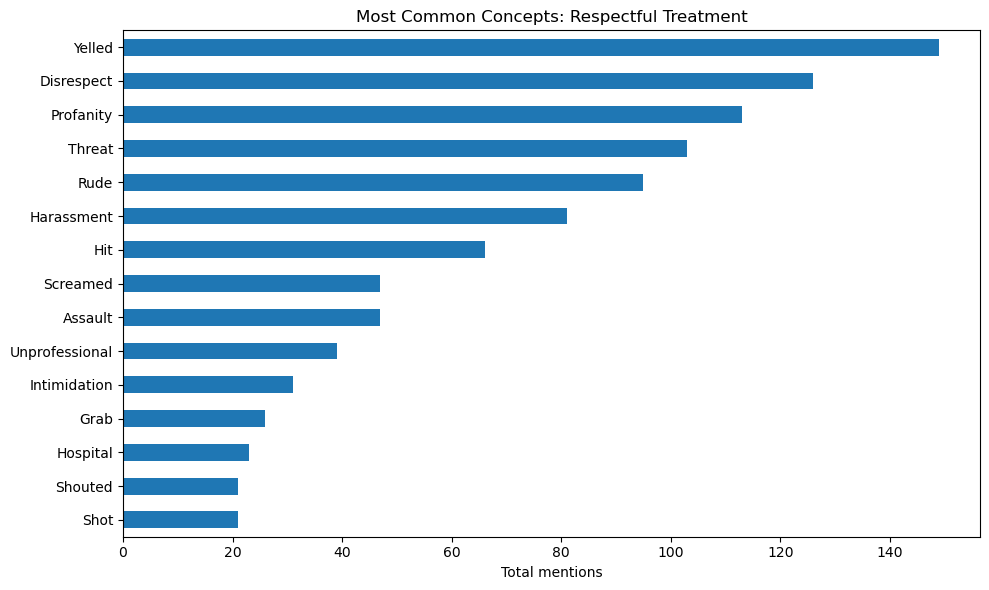

In [31]:
selected_category = df_complaints[CATEGORY_COL].value_counts().index[1]

category_data = df_complaints[df_complaints[CATEGORY_COL] == selected_category]

category_mentions = (
    category_data[list(KEYWORDS)]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 6))
category_mentions.plot(kind="barh")

plt.title(f"Most Common Concepts: {selected_category}")
plt.xlabel("Total mentions")
plt.tight_layout()
plt.show()

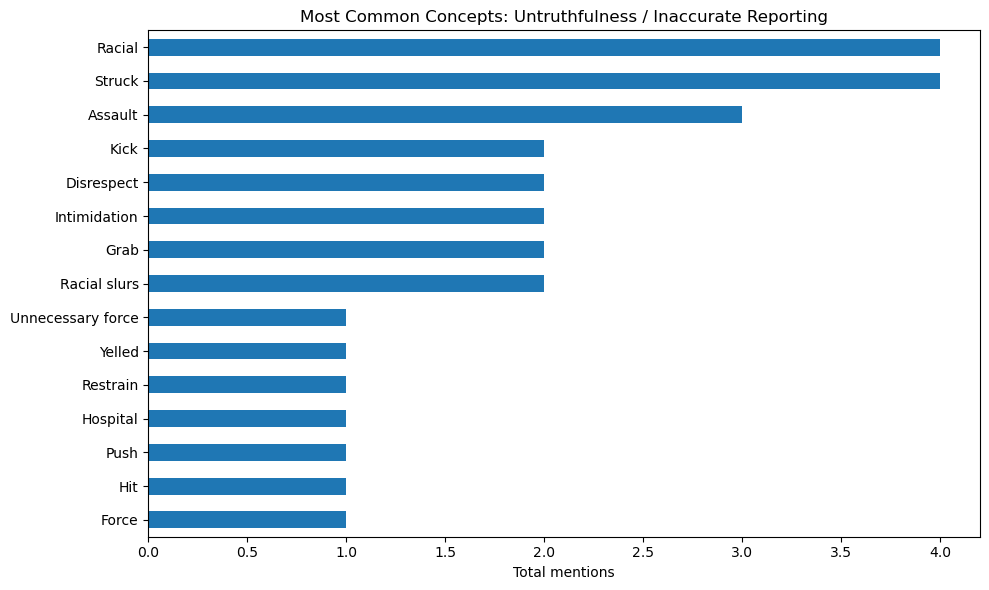

In [38]:
selected_category = df_complaints[CATEGORY_COL].value_counts().index[6]

category_data = df_complaints[df_complaints[CATEGORY_COL] == selected_category]

category_mentions = (
    category_data[list(KEYWORDS)]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 6))
category_mentions.plot(kind="barh")

plt.title(f"Most Common Concepts: {selected_category}")
plt.xlabel("Total mentions")
plt.tight_layout()
plt.show()

In [44]:
sorted_categories = df_complaints[CATEGORY_COL].value_counts().sort_values(ascending=False)
print(sorted_categories.head(20))

Neglect of Duty / Unreasonable Judgment    534
Respectful Treatment                       496
Use of Force                               148
Conduct Unbecoming                         116
Self Identification                         81
Conformance to Laws                         77
Untruthfulness / Inaccurate Reporting       59
Paid Details                                57
BIAS-Free Policing Policy                   57
Reporting for Duty                          43
Alcohol on Duty                             38
Alcohol in Police Facility                  34
Drug Testing / Controlled Substances        32
Directives / Orders                         30
Abuse of Process                            29
Alcohol off Duty                            28
Prisoner Handling / Booking Procedures      18
Harassment Policy / Sexual Harassment       14
Uniform & Equipment                         11
Vehicle Operation / Accidents               10
Name: allegation_clean, dtype: int64


In [60]:
df_pov = df_complaints[df_complaints["Incident type"] == "Citizen complaint"].count()
df_pov_total = df_complaints.count()
df_pov_percent_cc = (df_pov / df_pov_total) * 100
print(df_pov)
print(df_pov_percent_cc)

IA No                    1293
Incident type            1293
Received date            1293
Title/rank (snap)        1230
First name               1191
                         ... 
Unresponsive             1293
Death                    1293
Touched private parts    1293
Strip search             1293
Threatened to kill       1293
Length: 104, dtype: int64
IA No                    66.070516
Incident type            66.104294
Received date            63.011696
Title/rank (snap)        62.373225
First name               61.677887
                           ...    
Unresponsive             63.011696
Death                    63.011696
Touched private parts    63.011696
Strip search             63.011696
Threatened to kill       63.011696
Length: 104, dtype: float64


In [64]:
count = (df_complaints['Incident type'] == "Citizen complaint").sum()
count_total = df_complaints['Incident type'].count()
print(f'Total Citizen Complaints: {count}')
print(f'Total Incidents: {count_total}')
print(f'Percentage of Citizen Complaints: {count / count_total * 100:.2f}%')

Total Citizen Complaints: 1293
Total Incidents: 1956
Percentage of Citizen Complaints: 66.10%
